In [ ]:
KAVYASHREE ENG24CS0094 B1 06/10/2026 experiment 6

In [145]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_squared_error

In [146]:
df=pd.read_csv('./50_Startups (1) (1).csv')
df.head()

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [147]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing Spend  50 non-null     float64
 3   State            50 non-null     object 
 4   Profit           50 non-null     float64
dtypes: float64(4), object(1)
memory usage: 2.1+ KB


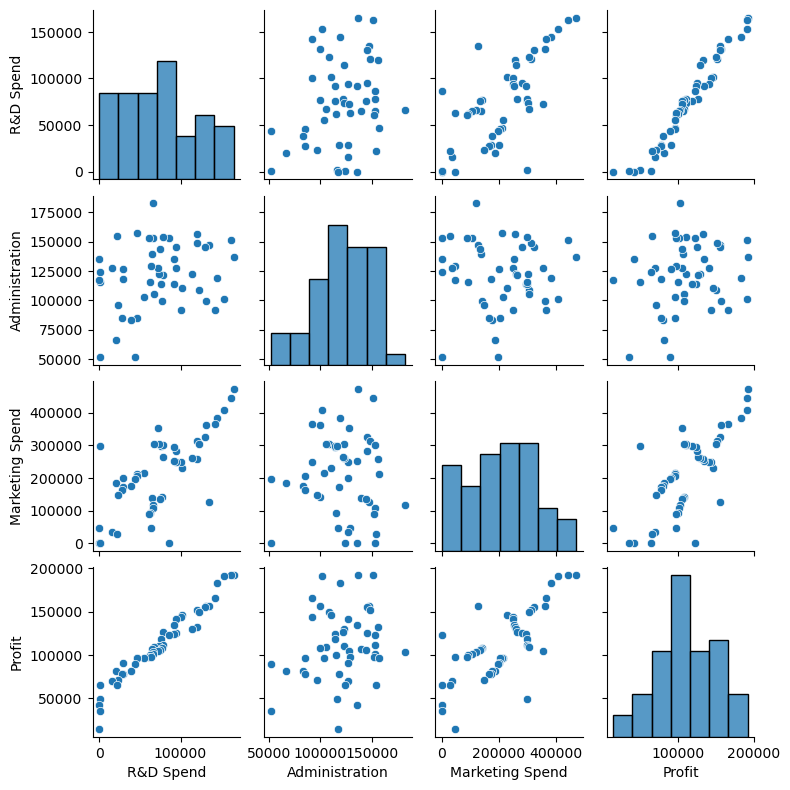

In [148]:
sns.pairplot(df,height=2)
plt.show()

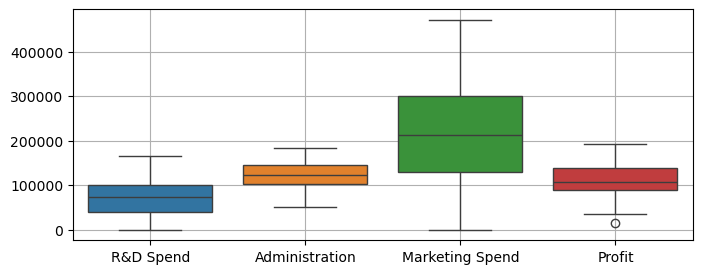

In [149]:
plt.figure(figsize=(8,3))
sns.boxplot(data=df)
plt.grid()
plt.show()

In [150]:
df.shape

(50, 5)

In [151]:
df=pd.get_dummies(
    data=df,columns=['State'],drop_first=True ,dtype=np.int64
)
df.head()

,R&D Spend,Administration,Marketing Spend,Profit,State_Florida,State_New York
0,165349.20,136897.80,471784.10,192261.83,0,1
1,162597.70,151377.59,443898.53,191792.06,0,0
2,153441.51,101145.55,407934.54,191050.39,1,0
3,144372.41,118671.85,383199.62,182901.99,0,1
4,142107.34,91391.77,366168.42,166187.94,1,0


In [152]:
cols = ['R&D Spend', 'Administration', 'Marketing Spend','Profit']

scaler = StandardScaler()
df[cols] = scaler.fit_transform(df[cols])
df.head()

,R&D Spend,Administration,Marketing Spend,Profit,State_Florida,State_New York
0,2.016411,0.560753,2.153943,2.011203,0,1
1,1.955860,1.082807,1.923600,1.999430,0,0
2,1.754364,-0.728257,1.626528,1.980842,1,0
3,1.554784,-0.096365,1.422210,1.776627,0,1
4,1.504937,-1.079919,1.281528,1.357740,1,0


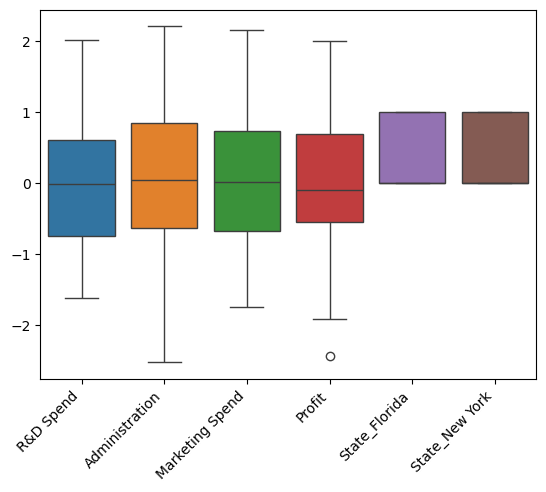

In [153]:
sns.boxplot(data=df)
plt.xticks(rotation=45, ha='right')
plt.show()

In [154]:
Q1=df.quantile(0.25)
Q3=df.quantile(0.75)
IQR=Q3-Q1
print(IQR)
ul=Q3+1.5*IQR
ll=Q1-1.5*IQR

df=df[-((df<ll)|(df>ul)).any(axis=1)]
df.shape

R&D Spend          1.357068
Administration     1.482225
Marketing Spend    1.405644
Profit             1.243753
State_Florida      1.000000
State_New York     1.000000
dtype: float64


(49, 6)

In [155]:
X=df.drop('Profit',axis=1).values
y=df.loc[:,'Profit'].values

In [156]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,random_state=1
)
X_train.shape,y_train.shape,X_test.shape,y_test.shape

((39, 5), (39,), (10, 5), (10,))

In [157]:
model=LinearRegression()
model.fit(X_train,y_train)

LinearRegression()

In [158]:
model.coef_

array([ 0.87740372, -0.04218498,  0.06661508, -0.05650074, -0.04923476])

In [159]:
model.intercept_

0.0532935862070803

In [160]:
predict=model.predict(X_test)
predict

array([ 0.04120213, -0.52915719, -0.58713586, -1.41920057,  1.67515091,
        1.46703762, -0.91011834, -0.25801214, -1.51943683, -0.28694085])

In [161]:
y_test

array([-0.17554233, -0.38344421, -0.77709368, -1.91321197,  1.98084225,
        1.77662724, -1.01536466, -0.27588222, -1.18008224, -0.3026246 ])

In [162]:
score=r2_score(predict,y_test)*100
score

93.57626677766746

In [163]:
mse=mean_squared_error(y_test,predict)
mse

0.06644382507849052